In [71]:
import requests
import pandas as pd
import warnings

#ignore warnings
warnings.filterwarnings('ignore')

#source data
url = "https://clinicaltrials.gov/api/v2/studies"

all_studies = []
page_token = None

#get upto 10,000 studies/records
while len(all_studies) < 10000:
    params = {
    "query.cond": "lung cancer",
    "pageSize": 1000,
    "format": "json"
    }
    
    if page_token:
        params["pageToken"] = page_token
    
    response = requests.get(url, params=params, timeout=60, verify = False)
    response.raise_for_status()
    
    data = response.json()
    all_studies.extend(data.get("studies", []))
    
    print(f"Loaded {len(all_studies)} studies")
    
    page_token = data.get("nextPageToken")
    if not page_token:
        break

all_studies = all_studies[:10000]
print("Total studies:", len(all_studies))

Loaded 1000 studies
Loaded 2000 studies
Loaded 3000 studies
Loaded 4000 studies
Loaded 5000 studies
Loaded 6000 studies
Loaded 7000 studies
Loaded 8000 studies
Loaded 9000 studies
Loaded 10000 studies
Total studies: 10000


In [72]:
#Print one study/record to understand the columns
all_studies[0]

{'protocolSection': {'identificationModule': {'nctId': 'NCT01273766',
   'orgStudyIdInfo': {'id': 'IRB00015287'},
   'secondaryIdInfos': [{'id': 'NCI-2010-02228',
     'type': 'OTHER_GRANT',
     'domain': 'NCI'},
    {'id': 'CCCWFU 97710',
     'type': 'OTHER',
     'domain': 'Wake Forest University Health Sciences'}],
   'organization': {'fullName': 'Wake Forest University Health Sciences',
    'class': 'OTHER'},
   'briefTitle': 'Deferasirox in Treating Iron Overload Caused By Blood Transfusions in Patients With Hematologic Malignancies',
   'officialTitle': 'Impact of Intervention With Deferasirox on the Immune Function of Patients With Hematologic Diseases and Transfusion-Related Iron Overload'},
  'statusModule': {'statusVerifiedDate': '2018-08',
   'overallStatus': 'COMPLETED',
   'expandedAccessInfo': {'hasExpandedAccess': False},
   'startDateStruct': {'date': '2011-01'},
   'primaryCompletionDateStruct': {'date': '2012-03', 'type': 'ACTUAL'},
   'completionDateStruct': {'date

In [75]:
#There are total of 19 modules. Only some of them look relvent to this analysis. Others are administrative purposes, misc, etc 
#so extracting the ones that look relevent

records = []

#convert json into dataframe
for study in all_studies:
    p = study.get("protocolSection", {})

    identification = p.get("identificationModule", {})
    status = p.get("statusModule", {})
    design = p.get("designModule", {})
    conditions = p.get("conditionsModule", {})
    eligibility = p.get("eligibilityModule", {})
    
    records.append({
        "nct_id": identification.get("nctId"),
        "title": identification.get("briefTitle"),
        "status": status.get("overallStatus"),
        "study_type": design.get("studyType"),
        "enrollment": design.get("enrollmentInfo", {}).get("count"),
        "conditions": conditions.get("conditions", []),
        "sex": eligibility.get("sex"),
        "minimum_age": eligibility.get("minimumAge"),
        "maximum_age": eligibility.get("maximumAge"),
        "eligibility_text": eligibility.get("eligibilityCriteria")
    })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 10)


,nct_id,title,status,study_type,enrollment,conditions,sex,minimum_age,maximum_age,eligibility_text
0,NCT01273766,Deferasirox in Treating Iron Overload Caused B...,COMPLETED,INTERVENTIONAL,16.0,"[Acute Undifferentiated Leukemia, Adult Acute ...",ALL,18 Years,None,Inclusion Criteria:\n\n* Patients must have a ...
1,NCT06165419,Definitive Radiation for High-Risk Spine Metas...,RECRUITING,INTERVENTIONAL,26.0,"[Metastatic Cancer, Metastatic Lung Cancer, Me...",ALL,18 Years,None,Eligible patients must have:\n\n* Any patholog...
2,NCT01946100,Treatment of Multifocal Lung Adenocarcinoma,TERMINATED,INTERVENTIONAL,100.0,"[Lung Neoplasms, Carcinoma Non-small-cell Lung...",ALL,18 Years,None,* Patient must be \> 18 years of age\n* Two or...
3,NCT07282444,A New Way to Share Radiation Therapy Plans Bet...,NOT_YET_RECRUITING,INTERVENTIONAL,194.0,"[Lung Carcinoma, Head and Neck Carcinoma]",ALL,18 Years,None,Inclusion Criteria:\n\n* PRACTICE: Must provid...
4,NCT00782366,Predictive Genetic Risk Assessment Trial,COMPLETED,OBSERVATIONAL,26.0,"[Colon Cancer, Lung Cancer, Atrial Fibrillatio...",ALL,18 Years,65 Years,Inclusion Criteria:\n\n* must be established E...


In [77]:
#understand the dataset

print("Rows and columns:", df.shape)
print("Unique trials:", df["nct_id"].nunique())
print("Duplicate NCT IDs:", df["nct_id"].duplicated().sum())

display(df.isnull().sum().sort_values(ascending=False))

Rows and columns: (10000, 10)
Unique trials: 10000
Duplicate NCT IDs: 0


maximum_age         7094
minimum_age          395
enrollment           166
sex                    4
eligibility_text       3
nct_id                 0
title                  0
status                 0
study_type             0
conditions             0
dtype: int64

In [79]:
#EDA: Analyze the data and perform data cleaning
df_clean = df.copy()

print("Dataset information:")
df_clean.info()

print("\nMissing values (%):")
display(
    (df_clean.isnull().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   nct_id            10000 non-null  object 
 1   title             10000 non-null  object 
 2   status            10000 non-null  object 
 3   study_type        10000 non-null  object 
 4   enrollment        9834 non-null   float64
 5   conditions        10000 non-null  object 
 6   sex               9996 non-null   object 
 7   minimum_age       9605 non-null   object 
 8   maximum_age       2906 non-null   object 
 9   eligibility_text  9997 non-null   object 
dtypes: float64(1), object(9)
memory usage: 781.4+ KB

Missing values (%):


maximum_age         70.94
minimum_age          3.95
enrollment           1.66
sex                  0.04
eligibility_text     0.03
nct_id               0.00
title                0.00
status               0.00
study_type           0.00
conditions           0.00
dtype: float64

In [81]:
#convert min_age_years and max_age_years into numeric values
import re
import numpy as np

def age_to_years(value):
    if pd.isna(value):
        return np.nan
    
    match = re.match(
        r"^\s*(\d+(?:\.\d+)?)\s*(Years?|Months?|Weeks?|Days?)\s*$",
        str(value),
        re.IGNORECASE
    )
    
    if not match:
        return np.nan
    
    number = float(match.group(1))
    unit = match.group(2).lower()
    
    if unit.startswith("year"):
        return number
    elif unit.startswith("month"):
        return number / 12
    elif unit.startswith("week"):
        return number / 52.18
    elif unit.startswith("day"):
        return number / 365.25

df_clean["min_age_years"] = (
    df_clean["minimum_age"].apply(age_to_years)
)

df_clean["max_age_years"] = (
    df_clean["maximum_age"].apply(age_to_years)
)

display(
    df_clean[
        ["minimum_age", "min_age_years",
        "maximum_age", "max_age_years"]
    ].head()
)

,minimum_age,min_age_years,maximum_age,max_age_years
0,18 Years,18.0,None,NaN
1,18 Years,18.0,None,NaN
2,18 Years,18.0,None,NaN
3,18 Years,18.0,None,NaN
4,18 Years,18.0,65 Years,65.0


In [83]:
#Extract useful features fro, conditions and eligibility modules
df_clean["condition_count"] = (
    df_clean["conditions"]
    .apply(lambda x: len(x) if isinstance(x, list) else 0)
)

df_clean["condition_text"] = (
    df_clean["conditions"]
    .apply(
        lambda x: "; ".join(x)
        if isinstance(x, list) else ""
    )
)

df_clean["eligibility_word_count"] = (
    df_clean["eligibility_text"]
    .fillna("")
    .str.split()
    .str.len()
)

df_clean["has_lung_cancer_condition"] = (
    df_clean["condition_text"]
        .str.contains(
            r"lung cancer|lung neoplasm|pulmonary carcinoma|"
            r"non.small.cell lung|small.cell lung|"
            r"lung adenocarcinoma",
            case=False,
            regex=True,
            na=False
        )
)

display(
    df_clean[
        ["nct_id", "condition_count",
        "eligibility_word_count",
        "has_lung_cancer_condition"]
    ].head()
)

#Check how many studies are for lung cancer
print("\nExplicit lung cancer condition flag:")
print(
    df_clean["has_lung_cancer_condition"]
    .value_counts()
)


,nct_id,condition_count,eligibility_word_count,has_lung_cancer_condition
0,NCT01273766,136,253,False
1,NCT06165419,8,132,True
2,NCT01946100,3,136,True
3,NCT07282444,2,423,False
4,NCT00782366,11,24,True



Explicit lung cancer condition flag:
has_lung_cancer_condition
True     7697
False    2303
Name: count, dtype: int64


In [85]:
#check the studies with has_lung_cancer_condition = False to ensure they are truly not related to lung cancer

non_matching = df_clean[
~df_clean["has_lung_cancer_condition"]
]

display(
non_matching[
["nct_id", "title", "condition_text"]
].head(20)
)

,nct_id,title,condition_text
0,NCT01273766,Deferasirox in Treating Iron Overload Caused B...,Acute Undifferentiated Leukemia; Adult Acute L...
3,NCT07282444,A New Way to Share Radiation Therapy Plans Bet...,Lung Carcinoma; Head and Neck Carcinoma
6,NCT06296745,Intrathecal Pemetrexed for Leptomeningeal Meta...,Leptomeningeal Metastasis
8,NCT04993677,A Study of SEA-CD40 Given With Other Drugs in ...,"Melanoma; Carcinoma, Non-Small- Cell Lung"
9,NCT01696981,Screening for Colorectal Cancer in Older Patie...,Colon Carcinoma; Rectal Carcinoma
21,NCT06048705,Study of GSK3901961 In Previously Treated Adva...,Neoplasms
31,NCT00780611,Investigating the Improvement in 4D CT Images ...,Cancer of the Lung; Abdominal Cancer
32,NCT00315211,Weekly Topotecan With Docetaxel in Recurrent S...,Mediastinal Neoplasms
33,NCT07079436,EIT Evaluation of Pulmonary Ventilation With D...,Intercostal Nerve Block; Pulmonary Ventilation...
36,NCT03449602,Minirigid Versus Conventional Rigid Thoracosco...,Pleural Effusion


In [87]:
#check whether lung cancer terminology appears in their titles:

non_matching = non_matching.copy()

non_matching["lung_cancer_in_title"] = (
non_matching["title"]
.fillna("")
.str.contains(
r"lung cancer|lung neoplasm|"
r"non.small.cell lung|small.cell lung|"
r"lung adenocarcinoma|lung Carcinoma|Cancer of the Lung",
case=False,
regex=True
)
)

print(
non_matching["lung_cancer_in_title"]
.value_counts()
)

lung_cancer_in_title
False    1799
True      504
Name: count, dtype: int64


In [89]:
#improve condition matching
import re

lung_cancer_terms = (
    r"lung cancer|"
    r"lung carcinoma|"
    r"lung neoplasm|"
    r"cancer of the lung|"
    r"non.small.cell.lung|"
    r"small.cell.lung|"
    r"\bNSCLC\b|"
    r"\bSCLC\b|"
    r"lung adenocarcinoma|"
    r"pulmonary carcinoma|"
    r"pulmonary neoplasm"
)

df_clean["lung_cancer_match_v2"] = (
    df_clean["condition_text"]
        .fillna("")
        .str.contains(
        lung_cancer_terms,
        case=False,
        regex=True
    )
)

print("Original matching:")
print(df_clean["has_lung_cancer_condition"].value_counts())

print("\nImproved matching:")
print(df_clean["lung_cancer_match_v2"].value_counts())

print("\nNewly identified trials:")
print(
(
    ~df_clean["has_lung_cancer_condition"]
        & df_clean["lung_cancer_match_v2"]
    ).sum()
)

Original matching:
has_lung_cancer_condition
True     7697
False    2303
Name: count, dtype: int64

Improved matching:
lung_cancer_match_v2
True     8196
False    1804
Name: count, dtype: int64

Newly identified trials:
499


Enrollment summary:


count    9.834000e+03
mean     1.816616e+03
std      6.714728e+04
min      0.000000e+00
25%      3.000000e+01
50%      7.000000e+01
75%      2.000000e+02
max      5.940299e+06
Name: enrollment, dtype: float64

Missing enrollment: 166
Zero enrollment: 328


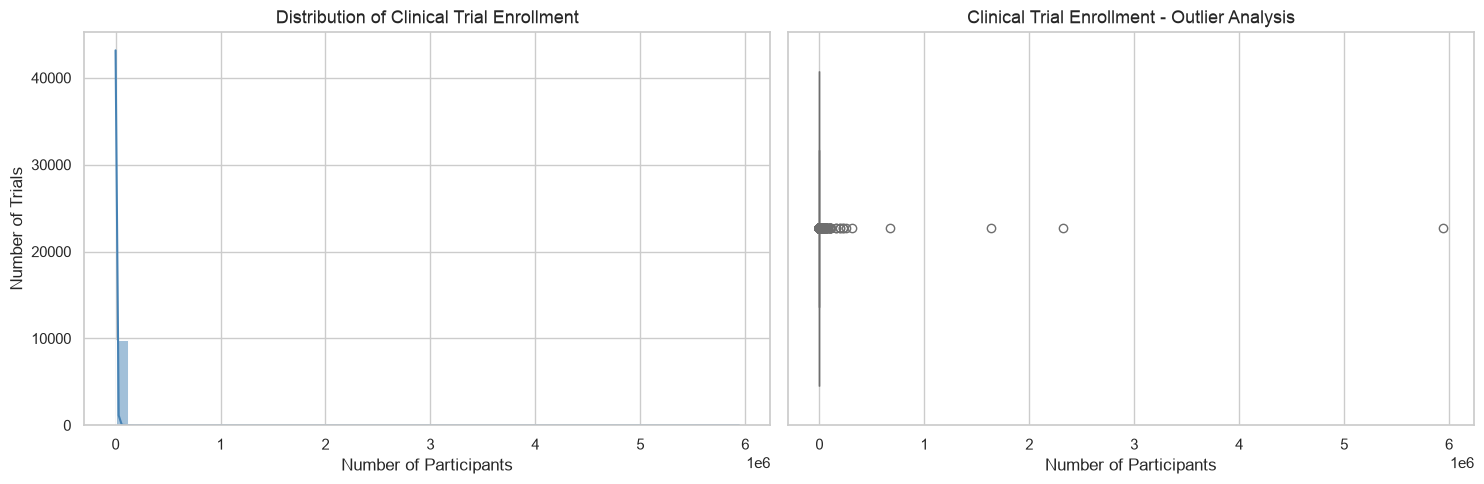

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set Seaborn theme
sns.set_theme(style="whitegrid")

# Enrollment summary statistics
print("Enrollment summary:")
display(df_clean["enrollment"].describe())

print("Missing enrollment:",
df_clean["enrollment"].isna().sum())

print("Zero enrollment:",
(df_clean["enrollment"] == 0).sum())

# Remove missing values for visualization
enrollment_data = df_clean["enrollment"].dropna()

# Create Seaborn visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Enrollment distribution
sns.histplot(
    x=enrollment_data,
    bins=50,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Clinical Trial Enrollment",
    fontsize=13
)
axes[0].set_xlabel("Number of Participants")
axes[0].set_ylabel("Number of Trials")

# Plot 2: Enrollment outlier analysis
sns.boxplot(
    x=enrollment_data,
    color="lightcoral",
    ax=axes[1]
)

axes[1].set_title(
    "Clinical Trial Enrollment - Outlier Analysis",
    fontsize=13
)
axes[1].set_xlabel("Number of Participants")

plt.tight_layout()
plt.show()


In [93]:
# Number of participants look really odd in the plots, however the Enrollment Summary shows count 9834 so possible some studies have larger number of patients and some have very less.
# Investigate unusually large enrollment values
# Clinical trial enrollment is highly right-skewed, with a median of 70 participants compared with a mean of approximately 18,166. 
# Extreme values reach nearly 5.94 million participants. 
# These values require further investigation by study type before determining whether they should be retained, transformed, or excluded.
largest_trials = df_clean.nlargest(
    15, "enrollment"
    )[
        ["nct_id", "title", "study_type",
        "status", "enrollment"]
    ]

display(largest_trials)

# Compare enrollment across study types
display(
    df_clean.groupby("study_type")["enrollment"]
    .agg(["count", "median", "mean", "max"])
    .round(1)
)


,nct_id,title,study_type,status,enrollment
4109,NCT03847753,Exploring the Comorbidity Between Mental Disor...,OBSERVATIONAL,COMPLETED,5940299.0
635,NCT01236053,Cancer in Patients With Gabapentin (GPRD),OBSERVATIONAL,COMPLETED,2323608.0
2648,NCT04506528,COVID EHR COHORT at the University of Wisconsin,OBSERVATIONAL,COMPLETED,1634381.0
8176,NCT04334239,Effectiveness of Care in Certified Cancer Cent...,OBSERVATIONAL,COMPLETED,670000.0
7729,NCT04125381,Arsenic Exposure and Lung Cancer Incidence,OBSERVATIONAL,COMPLETED,314000.0
8901,NCT05248412,The Long-term Spill-over Impact of COVID-19 on...,OBSERVATIONAL,UNKNOWN,250000.0
4235,NCT07646041,Annual Brain MRI Surveillance for Detection of...,OBSERVATIONAL,COMPLETED,229323.0
4807,NCT03330301,D-tecting Disease - From Exposure to Vitamin D...,OBSERVATIONAL,COMPLETED,222776.0
480,NCT03944447,Outcomes Mandate National Integration With Can...,INTERVENTIONAL,UNKNOWN,200000.0
1623,NCT03987633,EMPOWER-1: A Multi-site Clinical Cohort Resear...,OBSERVATIONAL,RECRUITING,200000.0


,count,median,mean,max
study_type,,,,
EXPANDED_ACCESS,0,NaN,NaN,NaN
INTERVENTIONAL,7691,60.0,301.0,200000.0
OBSERVATIONAL,2143,172.0,7255.8,5940299.0


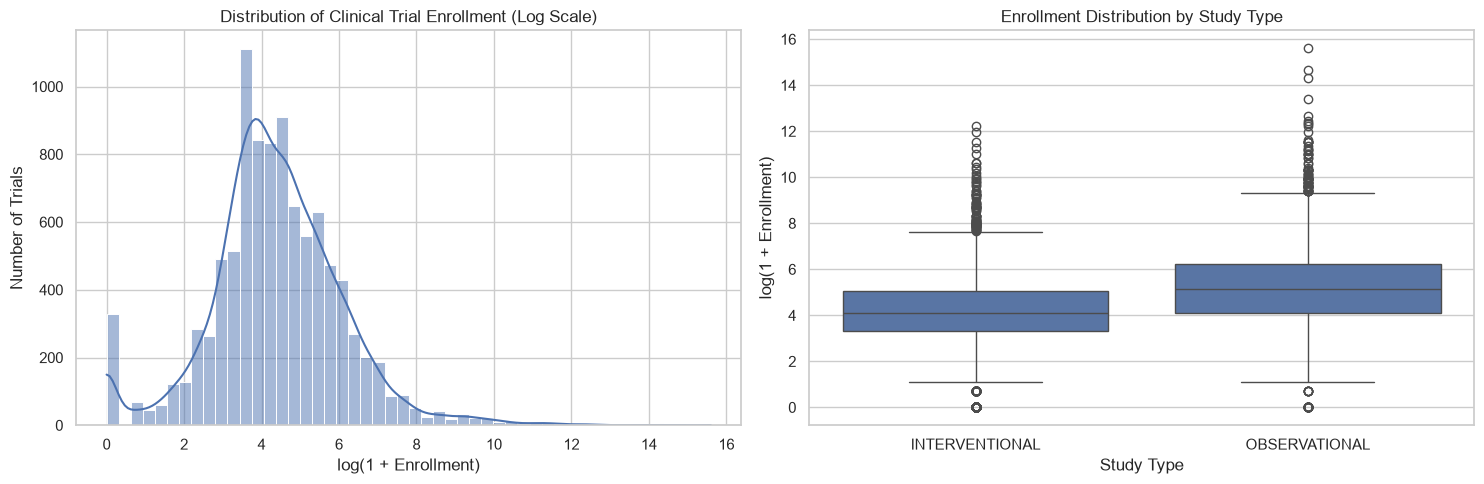

In [95]:
sns.set_theme(style="whitegrid")

# Keep original enrollment unchanged
plot_df = df_clean.dropna(
subset=["enrollment"]
).copy()

# log1p supports zero enrollment values
plot_df["log_enrollment"] = np.log1p(
plot_df["enrollment"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution on logarithmic scale
sns.histplot(
data=plot_df,
x="log_enrollment",
bins=50,
kde=True,
ax=axes[0]
)

axes[0].set_title(
"Distribution of Clinical Trial Enrollment (Log Scale)"
)
axes[0].set_xlabel("log(1 + Enrollment)")
axes[0].set_ylabel("Number of Trials")

# Boxplot by study type
sns.boxplot(
data=plot_df,
x="study_type",
y="log_enrollment",
ax=axes[1]
)

axes[1].set_title(
"Enrollment Distribution by Study Type"
)
axes[1].set_xlabel("Study Type")
axes[1].set_ylabel("log(1 + Enrollment)")

plt.tight_layout()
plt.show()

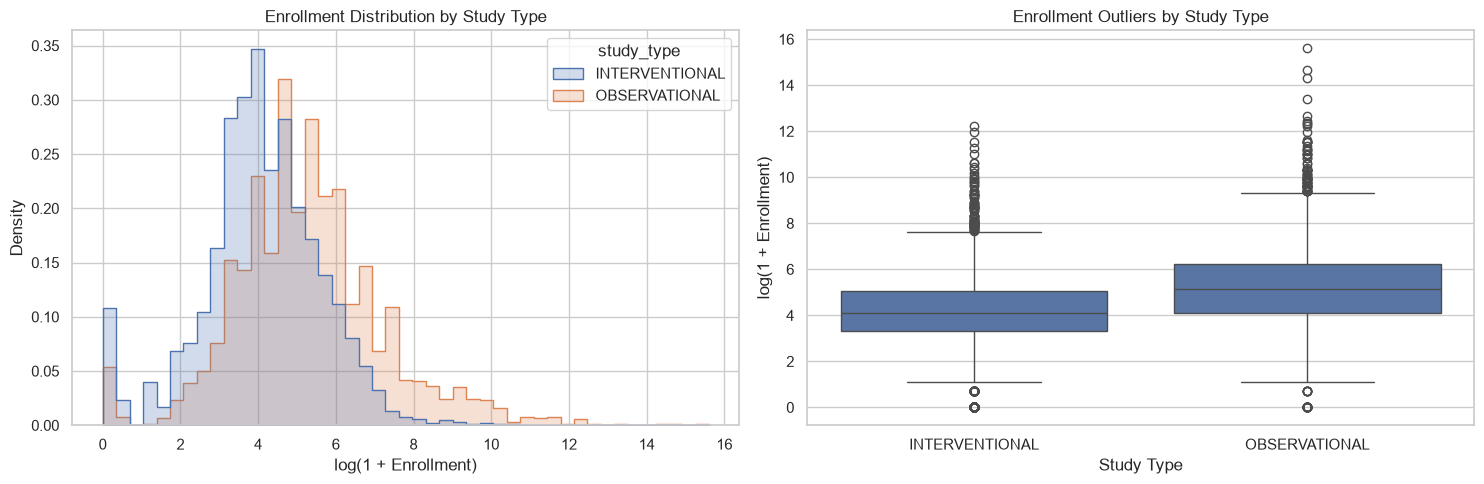

In [97]:
# Observational studies are driving most of the extreme enrollment values, 
# while interventional trials generally have much smaller participant populations.
sns.set_theme(style="whitegrid")

# Select studies with valid enrollment
plot_df = df_clean[
    df_clean["study_type"].isin(
        ["INTERVENTIONAL", "OBSERVATIONAL"]
    )
    & df_clean["enrollment"].notna()
    & (df_clean["enrollment"] >= 0)
].copy()

# The last plot was hard to visualize so using Log transform - for visualization only
plot_df["log_enrollment"] = np.log1p(
    plot_df["enrollment"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution by study type
sns.histplot(
    data=plot_df,
    x="log_enrollment",
    hue="study_type",
    bins=45,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[0]
)

axes[0].set_title(
    "Enrollment Distribution by Study Type"
)
axes[0].set_xlabel("log(1 + Enrollment)")
axes[0].set_ylabel("Density")

# Compare enrollment using boxplots
sns.boxplot(
    data=plot_df,
    x="study_type",
    y="log_enrollment",
    ax=axes[1]
)

axes[1].set_title(
    "Enrollment Outliers by Study Type"
)
axes[1].set_xlabel("Study Type")
axes[1].set_ylabel("log(1 + Enrollment)")

plt.tight_layout()
plt.show()

In [99]:
zero_enrollment = df_clean[
    df_clean["enrollment"] == 0
]

print("Zero enrollment trials by status:")

display(
    zero_enrollment["status"].value_counts()
)

Zero enrollment trials by status:


status
WITHDRAWN    328
Name: count, dtype: int64

In [101]:
# Analyze missing enrollment by study type and status
missing_enrollment = df_clean[
    df_clean["enrollment"].isna()
]

print("Missing enrollment by study type:")
display(missing_enrollment["study_type"].value_counts())

print("\nMissing enrollment by recruitment status:")
display(missing_enrollment["status"].value_counts())

# Cross-tabulation
display(
    pd.crosstab(
        missing_enrollment["study_type"],
        missing_enrollment["status"]
    )
)


Missing enrollment by study type:


study_type
INTERVENTIONAL     116
EXPANDED_ACCESS     40
OBSERVATIONAL       10
Name: count, dtype: int64


Missing enrollment by recruitment status:


status
COMPLETED                    87
UNKNOWN                      34
NO_LONGER_AVAILABLE          19
APPROVED_FOR_MARKETING       12
AVAILABLE                     7
TERMINATED                    5
TEMPORARILY_NOT_AVAILABLE     2
Name: count, dtype: int64

status,APPROVED_FOR_MARKETING,AVAILABLE,COMPLETED,NO_LONGER_AVAILABLE,TEMPORARILY_NOT_AVAILABLE,TERMINATED,UNKNOWN
study_type,,,,,,,
EXPANDED_ACCESS,12,7,0,19,2,0,0
INTERVENTIONAL,0,0,83,0,0,5,28
OBSERVATIONAL,0,0,4,0,0,0,6



Majority-class dummy
                  precision    recall  f1-score   support

No keyword match       0.00      0.00      0.00       361
   Keyword match       0.82      1.00      0.90      1639

        accuracy                           0.82      2000
       macro avg       0.41      0.50      0.45      2000
    weighted avg       0.67      0.82      0.74      2000


TF-IDF + Logistic Regression
                  precision    recall  f1-score   support

No keyword match       0.46      0.68      0.55       361
   Keyword match       0.92      0.83      0.87      1639

        accuracy                           0.80      2000
       macro avg       0.69      0.75      0.71      2000
    weighted avg       0.84      0.80      0.81      2000


Holdout evaluation (20% test set):
                       model  accuracy  precision  recall    f1
        Majority-class dummy     0.820      0.820   1.000 0.901
TF-IDF + Logistic Regression     0.801      0.921   0.828 0.872


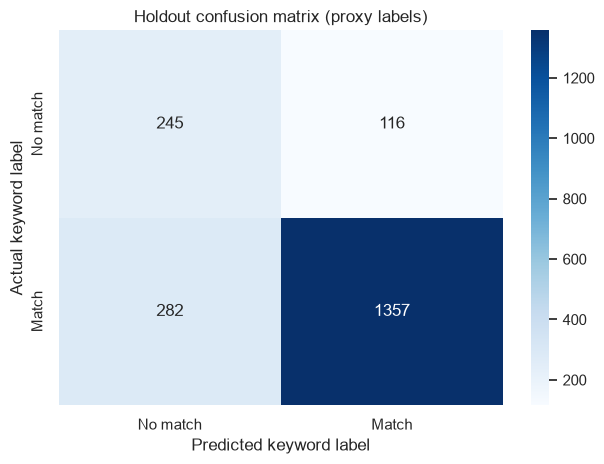


Note: This evaluates prediction of a condition-field keyword flag, NOT clinical relevance or patient-trial eligibility.


In [103]:
#Baseline model
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, confusion_matrix,precision_score, recall_score, f1_score, accuracy_score)

required = {'title', 'eligibility_text', 'lung_cancer_match_v2'}
assert required.issubset(df_clean.columns), f'Missing columns: {required - set(df_clean.columns)}'
model_df = df_clean.copy()
model_df['model_text'] = (model_df['title'].fillna('') + ' ' +
model_df['eligibility_text'].fillna('')).str.strip()
model_df = model_df[model_df['model_text'].ne('')].copy()
X = model_df['model_text']
y = model_df['lung_cancer_match_v2'].astype(int)
assert y.nunique() == 2, 'Need both classes for classification'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', min_df=2,
        max_features=10000, ngram_range=(1, 2))),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
dummy = DummyClassifier(strategy='most_frequent')
results = []
for name, estimator in [('Majority-class dummy', dummy), ('TF-IDF + Logistic Regression', baseline)]:
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predictions),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0),
        'f1': f1_score(y_test, predictions, zero_division=0),
    })
    print(f'\n{name}')
    print(classification_report(y_test, predictions, target_names=['No keyword match', 'Keyword match'], zero_division=0))

scores = pd.DataFrame(results)
print('\nHoldout evaluation (20% test set):')
print(scores.round(3).to_string(index=False))

predictions = baseline.predict(X_test)
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=['No match', 'Match'], yticklabels=['No match', 'Match'])
plt.title('Holdout confusion matrix (proxy labels)')
plt.xlabel('Predicted keyword label')
plt.ylabel('Actual keyword label')
plt.tight_layout()
plt.show()

print('\nNote: This evaluates prediction of a condition-field keyword flag, NOT clinical relevance or patient-trial eligibility.')